# Swin-UNET + GLCB: **Tumor-Only Segmentation**
> **Task:** Binary segmentation where  
> - **Class 0 (background):** liver tissue + background  
> - **Class 1 (foreground):** tumor region only  

Masks are expected to have pixel intensities:  
| Tissue | Typical pixel value |
|--------|--------------------|
| Background | 0 |
| Liver | ~127 (or any value 1-254 that is not 255) |
| Tumor | 255 |

The preprocessing step converts these to **binary tumor masks** (0 or 1).

In [3]:
!pip install git+https://github.com/lucasb-eyer/pydensecrf.git

  Cloning https://github.com/lucasb-eyer/pydensecrf.git to /tmp/pip-req-build-gp8jtapo
  Running command git clone --filter=blob:none --quiet https://github.com/lucasb-eyer/pydensecrf.git /tmp/pip-req-build-gp8jtapo
  Resolved https://github.com/lucasb-eyer/pydensecrf.git to commit 2723c7fa4f2ead16ae1ce3d8afe977724bb8f87f
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pydensecrf: filename=pydensecrf-1.0-cp312-cp312-linux_x86_64.whl size=3494532 sha256=35287a8af0212ff69a65e5dc80e529f492427cd0d5d4945893c0a062cd61dc51
  Stored in directory: /tmp/pip-ephem-wheel-cache-7h_22eex/wheels/5f/63/9b/ad8357747651277615ec2094c768471e8ecde7d7b53564f24d
Successfully built pydensecrf


In [2]:
import tensorflow as tf
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)

import os
import glob
import cv2
import sys
import math
import re

import keras as ks
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap

from tqdm.notebook import tqdm
from PIL import Image

import skimage.io as io
import skimage.transform as trans

from tensorflow.python.keras.optimizers import TFOptimizer
from tensorflow.keras import backend as K
from keras.models import Model
from tensorflow import expand_dims
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
from tensorflow.compat.v1 import image
from tensorflow.keras.layers import (MaxPooling2D, AveragePooling2D, UpSampling2D,
    Conv2DTranspose, GlobalAveragePooling2D, Conv2D, DepthwiseConv2D, Lambda,
    BatchNormalization, Activation, concatenate, multiply, add,
    ReLU, LeakyReLU, PReLU, ELU, Softmax, Layer)
from tensorflow import math
import tensorflow.keras.backend as K
from tensorflow.nn import depth_to_space
from tensorflow.image import extract_patches
from tensorflow.keras.layers import (Dense, Embedding, Dropout,
    LayerNormalization)
from tensorflow.keras.activations import softmax
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from keras.layers import *
from keras.optimizers import *
from keras.callbacks import ModelCheckpoint, LearningRateScheduler
from keras import backend as keras

from sklearn.model_selection import train_test_split

print('TF version:', tf.__version__)
print('GPU available:', bool(gpus))


TF version: 2.19.0
GPU available: True


## ⚙️ Configuration & Data Loading

In [4]:
# ─── Paths ────────────────────────────────────────────────────────────────
image_dir = '/kaggle/input/datasets/ag3ntsp1d3rx/litsdataset2/images'
mask_dir  = '/kaggle/input/datasets/ag3ntsp1d3rx/litsdataset2/masks'

# ─── Global hyperparams ────────────────────────────────────────────────────
TARGET_SIZE  = (256, 256)
BATCH_SIZE   = 4
TUMOR_THRESHOLD = 200   # pixel value ≥ this → tumor (class 1)
                        # liver pixels (~127) and background (0) → class 0

image_filenames = sorted(os.listdir(image_dir))
mask_filenames  = sorted(os.listdir(mask_dir))

print(f'Total images : {len(image_filenames)}')
print(f'Total masks  : {len(mask_filenames)}')
print('Sample image:', image_filenames[:3])
print('Sample mask :', mask_filenames[:3])

train_images, val_images, train_masks, val_masks = train_test_split(
    image_filenames, mask_filenames, test_size=0.2, random_state=42
)
print(f'\nTrain: {len(train_images)}  |  Val: {len(val_images)}')


Total images : 58638
Total masks  : 58638
Sample image: ['Volume-000-000.png', 'Volume-000-001.png', 'Volume-000-002.png']
Sample mask : ['Volume-000-000.png', 'Volume-000-001.png', 'Volume-000-002.png']

Train: 46910  |  Val: 11728


## 🔬 Mask Conversion — Tumor-Only
The raw mask has three intensity classes. We collapse them to:
```
raw pixel ≥ TUMOR_THRESHOLD (≈255)  →  1  (tumor)
raw pixel <  TUMOR_THRESHOLD         →  0  (liver + background)
```

In [5]:
def load_tumor_mask(mask_path, target_size, tumor_threshold=200):
    """
    Load a liver-tumour mask and convert it to a **binary tumour-only** mask.

    Parameters
    ----------
    mask_path       : str   – full path to the mask image
    target_size     : tuple – (H, W)
    tumor_threshold : int   – pixel values >= this are treated as tumour

    Returns
    -------
    np.ndarray of shape (H, W, 1), dtype float32, values in {0, 1}
    """
    # Load as greyscale (0-255)
    mask = load_img(mask_path, target_size=target_size, color_mode='grayscale')
    mask = img_to_array(mask)          # shape (H, W, 1), float32 0-255
    # Threshold: only tumor pixels become 1
    tumor_mask = (mask >= tumor_threshold).astype(np.float32)
    return tumor_mask                   # shape (H, W, 1)


def load_image(image_path, target_size):
    img = load_img(image_path, target_size=target_size)
    return img_to_array(img) / 255.0   # shape (H, W, 3), float32


## 📊 Pre-Training Visualizations

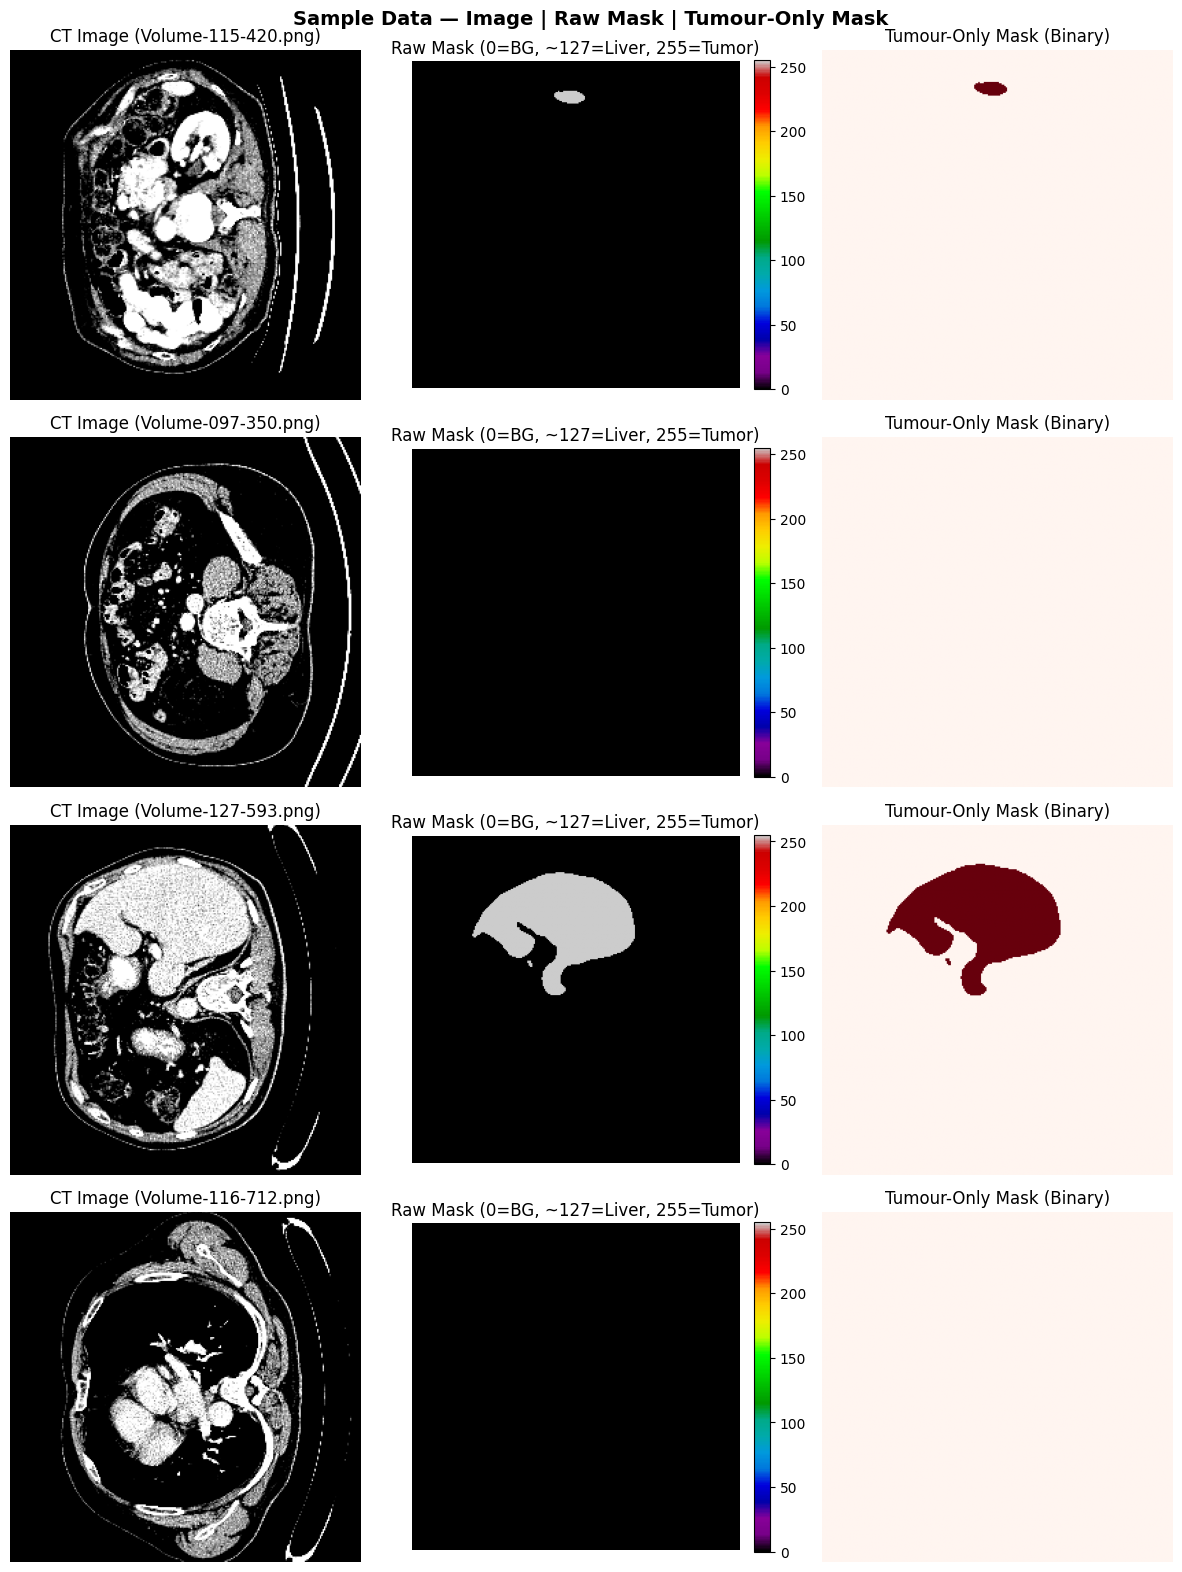

In [22]:
# ── 1. Sample images, raw masks, and TUMOUR masks side-by-side ──────────────
N_VIZ = 4
sample_imgs  = train_images[:N_VIZ]
sample_masks = train_masks[:N_VIZ]

fig, axes = plt.subplots(N_VIZ, 3, figsize=(12, 4 * N_VIZ))
fig.suptitle('Sample Data — Image | Raw Mask | Tumour-Only Mask', fontsize=14, fontweight='bold')

for i, (img_f, msk_f) in enumerate(zip(sample_imgs, sample_masks)):
    img       = load_image(os.path.join(image_dir, img_f), TARGET_SIZE)
    raw_mask  = load_img(os.path.join(mask_dir, msk_f),
                         target_size=TARGET_SIZE, color_mode='grayscale')
    raw_mask  = img_to_array(raw_mask)
    tumor_msk = load_tumor_mask(os.path.join(mask_dir, msk_f), TARGET_SIZE, TUMOR_THRESHOLD)

    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f'CT Image ({img_f[:20]})')
    axes[i, 0].axis('off')

    im1 = axes[i, 1].imshow(raw_mask.squeeze(), cmap='nipy_spectral', vmin=0, vmax=255)
    axes[i, 1].set_title('Raw Mask (0=BG, ~127=Liver, 255=Tumor)')
    axes[i, 1].axis('off')
    plt.colorbar(im1, ax=axes[i, 1], fraction=0.046, pad=0.04)

    axes[i, 2].imshow(tumor_msk.squeeze(), cmap='Reds', vmin=0, vmax=1)
    axes[i, 2].set_title('Tumour-Only Mask (Binary)')
    axes[i, 2].axis('off')

plt.tight_layout()
plt.show()


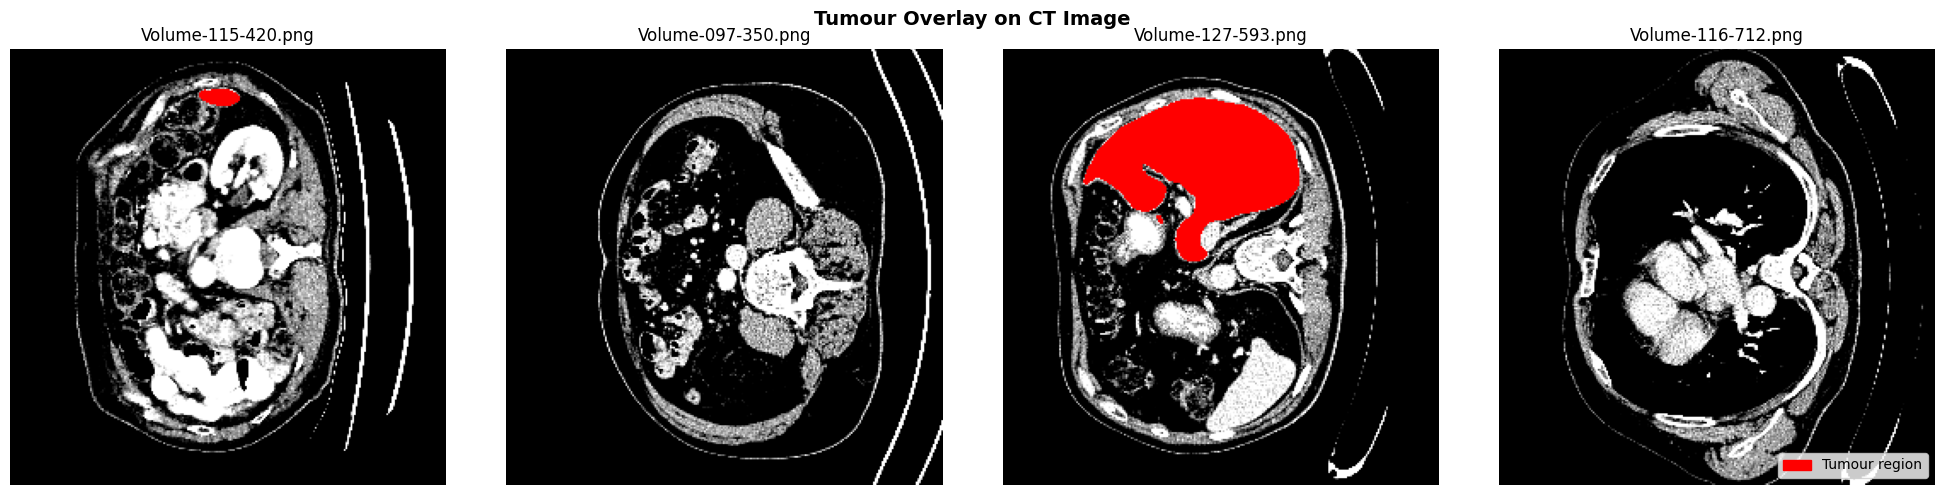

In [23]:
# ── 2. Tumour overlay on CT image ────────────────────────────────────────────
fig, axes = plt.subplots(1, N_VIZ, figsize=(5 * N_VIZ, 5))
fig.suptitle('Tumour Overlay on CT Image', fontsize=14, fontweight='bold')

for i, (img_f, msk_f) in enumerate(zip(sample_imgs, sample_masks)):
    img       = load_image(os.path.join(image_dir, img_f), TARGET_SIZE)
    tumor_msk = load_tumor_mask(os.path.join(mask_dir, msk_f), TARGET_SIZE, TUMOR_THRESHOLD)
    overlay   = img.copy()
    overlay[tumor_msk.squeeze() == 1, 0] = 1.0  # red channel
    overlay[tumor_msk.squeeze() == 1, 1] = 0.0
    overlay[tumor_msk.squeeze() == 1, 2] = 0.0

    axes[i].imshow(overlay)
    axes[i].set_title(img_f[:20])
    axes[i].axis('off')

red_patch = mpatches.Patch(color='red', label='Tumour region')
plt.legend(handles=[red_patch], loc='lower right', fontsize=10)
plt.tight_layout()
plt.show()


In [24]:
# # ── 3. Class distribution in the dataset ─────────────────────────────────────
# print('Computing class distribution on training set (this may take a moment)...')
# tumor_px_total = 0
# non_tumor_total = 0
# tumor_slice_count = 0

# for msk_f in tqdm(train_masks):
#     m = load_tumor_mask(os.path.join(mask_dir, msk_f), TARGET_SIZE, TUMOR_THRESHOLD)
#     t = m.sum()
#     tumor_px_total += t
#     non_tumor_total += (TARGET_SIZE[0] * TARGET_SIZE[1]) - t
#     if t > 0:
#         tumor_slice_count += 1

# total_px = tumor_px_total + non_tumor_total
# print(f'\nTumour pixels    : {int(tumor_px_total):,}  ({100*tumor_px_total/total_px:.2f}%)')
# print(f'Non-tumour pixels: {int(non_tumor_total):,}  ({100*non_tumor_total/total_px:.2f}%)')
# print(f'Slices with tumour: {tumor_slice_count} / {len(train_masks)}')

# fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# fig.suptitle('Training Set — Class Distribution', fontsize=13, fontweight='bold')

# # Pie chart
# axes[0].pie(
#     [non_tumor_total, tumor_px_total],
#     labels=['Liver + Background', 'Tumour'],
#     colors=['#4a90d9', '#e74c3c'],
#     autopct='%1.2f%%', startangle=90,
#     textprops={'fontsize': 11}
# )
# axes[0].set_title('Pixel-Level Class Balance')

# # Bar chart
# axes[1].bar(['Liver + BG', 'Tumour'],
#             [non_tumor_total, tumor_px_total],
#             color=['#4a90d9', '#e74c3c'], edgecolor='black')
# axes[1].set_ylabel('Total pixels (training set)')
# axes[1].set_title('Absolute Pixel Counts')
# for bar, val in zip(axes[1].patches, [non_tumor_total, tumor_px_total]):
#     axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height()*1.01,
#                  f'{int(val):,}', ha='center', va='bottom', fontsize=10)

# plt.tight_layout()
# plt.show()

# # Compute positive weight for weighted BCE
# pos_weight = non_tumor_total / (tumor_px_total + 1e-6)
# print(f'\nRecommended pos_weight for weighted BCE: {pos_weight:.1f}x')


## 🔄 Data Generator (Tumor-Only Masks)

In [6]:
# def image_mask_generator(image_dir, mask_dir, image_filenames, mask_filenames,
#                           batch_size, target_size, tumor_threshold=200,
#                           augment=False):
#     """
#     Yields (images, tumor_masks) batches.
#     Masks are binary: 1 = tumour, 0 = liver + background.
#     """
#     n = len(image_filenames)
#     indices = np.arange(n)
#     while True:
#         np.random.shuffle(indices)
#         for start in range(0, n, batch_size):
#             batch_idx = indices[start : start + batch_size]
#             batch_images, batch_masks = [], []
#             for i in batch_idx:
#                 img = load_image(os.path.join(image_dir, image_filenames[i]), target_size)
#                 msk = load_tumor_mask(os.path.join(mask_dir, mask_filenames[i]),
#                                      target_size, tumor_threshold)
#                 # Optional light augmentation
#                 if augment and np.random.rand() > 0.5:
#                     img = img[:, ::-1, :]   # horizontal flip
#                     msk = msk[:, ::-1, :]
#                 if augment and np.random.rand() > 0.5:
#                     img = img[::-1, :, :]   # vertical flip
#                     msk = msk[::-1, :, :]
#                 batch_images.append(img)
#                 batch_masks.append(msk)
#             yield np.array(batch_images), np.array(batch_masks)


def image_mask_generator(image_dir, mask_dir, image_filenames, mask_filenames,
                          batch_size, target_size, tumor_threshold=200,
                          augment=False):
    n = len(image_filenames)
    indices = np.arange(n)
    while True:
        np.random.shuffle(indices)
        for start in range(0, n, batch_size):
            batch_idx = indices[start : start + batch_size]
            batch_images, batch_masks = [], []
            for i in batch_idx:
                img = load_image(os.path.join(image_dir, image_filenames[i]), target_size)
                msk = load_tumor_mask(os.path.join(mask_dir, mask_filenames[i]),
                                     target_size, tumor_threshold)

                # Augmentation
                if augment and np.random.rand() > 0.5:
                    img = img[:, ::-1, :]      # horizontal flip
                    msk = msk[:, ::-1, :]
                if augment and np.random.rand() > 0.5:
                    img = img[::-1, :, :]      # vertical flip
                    msk = msk[::-1, :, :]

                # FIX: Add channel dimension to mask
                # msk = np.expand_dims(msk, axis=-1)   # (256,256) → (256,256,1)

                batch_images.append(img)
                batch_masks.append(msk)
            yield np.array(batch_images), np.array(batch_masks)


train_gen = image_mask_generator(image_dir, mask_dir, train_images, train_masks,
                                 BATCH_SIZE, TARGET_SIZE, TUMOR_THRESHOLD, augment=True)
val_gen   = image_mask_generator(image_dir, mask_dir, val_images, val_masks,
                                 BATCH_SIZE, TARGET_SIZE, TUMOR_THRESHOLD, augment=False)



Image batch shape : (4, 256, 256, 3)   range: 0.0 - 1.0
Mask  batch shape : (4, 256, 256, 1)   unique values: [0. 1.]


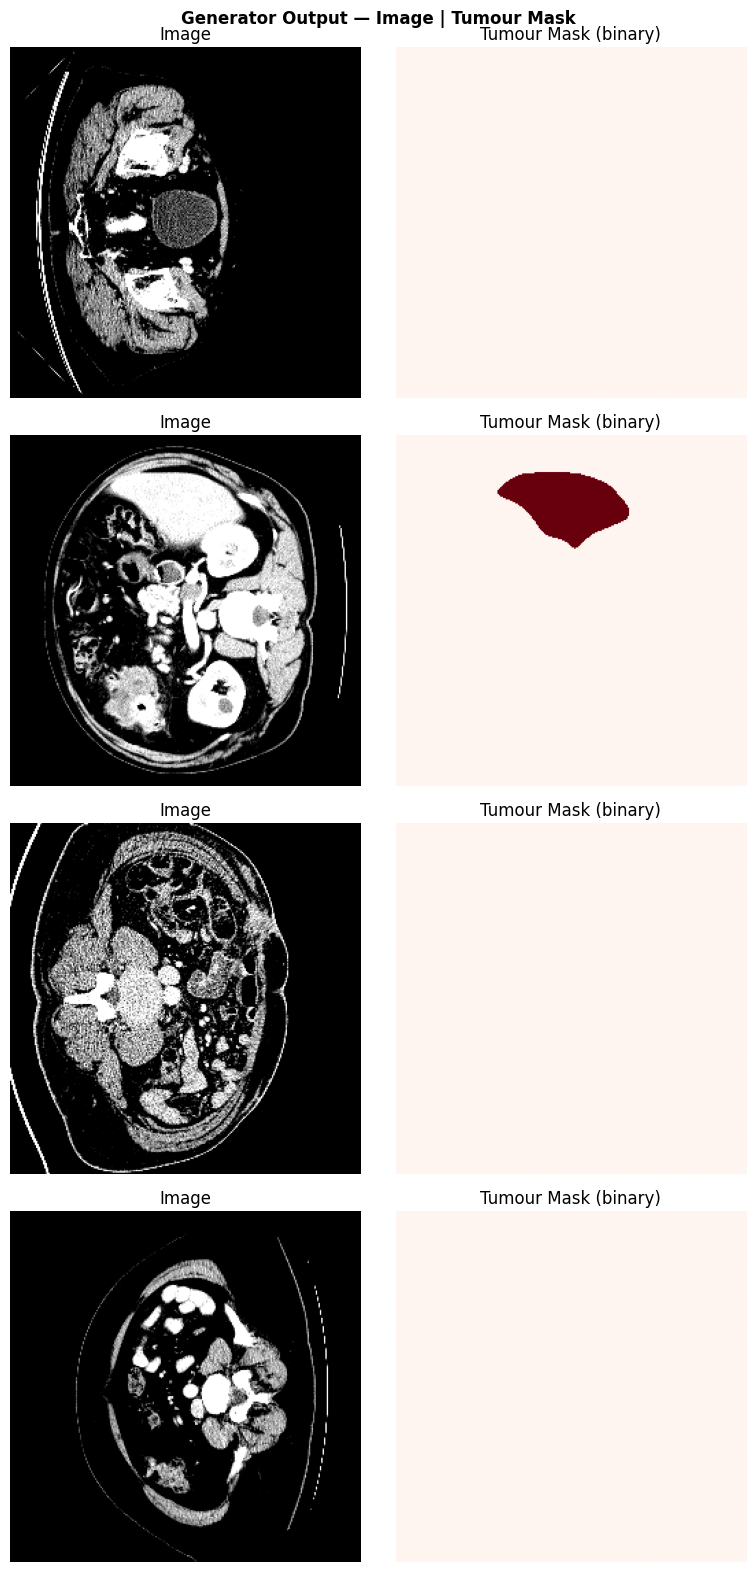

In [75]:
# ── Quick sanity-check of generator output ────────────────────────────────────
batch_imgs, batch_masks = next(train_gen)
print('Image batch shape :', batch_imgs.shape,  '  range:', batch_imgs.min().round(2), '-', batch_imgs.max().round(2))
print('Mask  batch shape :', batch_masks.shape, '  unique values:', np.unique(batch_masks))

fig, axes = plt.subplots(BATCH_SIZE, 2, figsize=(8, 4 * BATCH_SIZE))
fig.suptitle('Generator Output — Image | Tumour Mask', fontsize=12, fontweight='bold')
for i in range(BATCH_SIZE):
    axes[i, 0].imshow(batch_imgs[i])
    axes[i, 0].set_title('Image'); axes[i, 0].axis('off')
    axes[i, 1].imshow(batch_masks[i].squeeze(), cmap='Reds', vmin=0, vmax=1)
    axes[i, 1].set_title('Tumour Mask (binary)'); axes[i, 1].axis('off')
plt.tight_layout(); plt.show()


## 🏗️ Model Architecture — Swin-UNET + GLCB
All architecture code is preserved verbatim. The only change is that the model
outputs a **single-channel sigmoid map** (unchanged from original) — which now
represents **tumour probability** instead of liver+tumour probability.

In [7]:
# ─── Patch operations ────────────────────────────────────────────────────────
@ks.saving.register_keras_serializable()
class patch_extract(Layer):
    def __init__(self, patch_size, **kwargs):
        super(patch_extract, self).__init__(**kwargs)
        self.patch_size   = patch_size
        self.patch_size_x = patch_size[0]
        self.patch_size_y = patch_size[0]
    def call(self, images):
        batch_size = tf.shape(images)[0]
        patches = extract_patches(images=images,
                                  sizes=(1, self.patch_size_x, self.patch_size_y, 1),
                                  strides=(1, self.patch_size_x, self.patch_size_y, 1),
                                  rates=(1, 1, 1, 1), padding='VALID')
        patch_dim = patches.shape[-1]
        patch_num = patches.shape[1]
        patches   = tf.reshape(patches, (batch_size, patch_num*patch_num, patch_dim))
        return patches
    def get_config(self):
        config = super().get_config().copy()
        config.update({'patch_size': self.patch_size})
        return config
    @classmethod
    def from_config(cls, config): return cls(**config)

@ks.saving.register_keras_serializable()
class patch_embedding(Layer):
    def __init__(self, num_patch, embed_dim, **kwargs):
        super(patch_embedding, self).__init__(**kwargs)
        self.num_patch = num_patch
        self.embed_dim = embed_dim
        self.proj      = Dense(embed_dim)
        self.pos_embed = Embedding(input_dim=num_patch, output_dim=embed_dim)
    def get_config(self):
        config = super().get_config().copy()
        config.update({'num_patch': self.num_patch, 'embed_dim': self.embed_dim})
        return config
    @classmethod
    def from_config(cls, config): return cls(**config)
    def call(self, patch):
        pos   = tf.range(start=0, limit=self.num_patch, delta=1)
        embed = self.proj(patch) + self.pos_embed(pos)
        return embed

@ks.saving.register_keras_serializable()
class patch_merging(tf.keras.layers.Layer):
    def __init__(self, num_patch, embed_dim, name='', **kwargs):
        super(patch_merging, self).__init__(**kwargs)
        self.num_patch  = num_patch
        self.embed_dim  = embed_dim
        self.linear_trans = Dense(2*embed_dim, use_bias=False,
                                  name='{}_linear_trans'.format(name))
    def get_config(self):
        config = super().get_config().copy()
        config.update({'num_patch': self.num_patch, 'embed_dim': self.embed_dim, 'name': self.name})
        return config
    @classmethod
    def from_config(cls, config): return cls(**config)
    def call(self, x):
        H, W   = self.num_patch
        B, L, C = x.get_shape().as_list()
        
        assert (L == H * W)
        assert (H % 2 == 0 and W % 2 == 0)
        
        x  = tf.reshape(x, shape=(-1, H, W, C))
        
        # ✅ FIX: cast slice indices to int
        x0 = x[:, 0::2, 0::2, :]; x1 = x[:, 1::2, 0::2, :]
        x2 = x[:, 0::2, 1::2, :]; x3 = x[:, 1::2, 1::2, :]
        x  = tf.concat((x0, x1, x2, x3), axis=-1)
        
        x  = tf.reshape(x, shape=(-1, (int(H)//2)*(int(W)//2), 4*int(C)))
        x  = self.linear_trans(x)
        return x

@ks.saving.register_keras_serializable()
class patch_expanding(tf.keras.layers.Layer):
    def __init__(self, num_patch, embed_dim, upsample_rate, return_vector=True, name='patch_expand', **kwargs):
        super(patch_expanding, self).__init__(**kwargs)
        self.num_patch    = num_patch
        self.embed_dim    = embed_dim
        self.upsample_rate = upsample_rate
        self.return_vector = return_vector
        self.linear_trans1 = Conv2D(upsample_rate*embed_dim, kernel_size=1, use_bias=False,
                                    name='{}_linear_trans1'.format(name))
        self.linear_trans2 = Conv2D(upsample_rate*embed_dim, kernel_size=1, use_bias=False,
                                    name='{}_linear_trans1'.format(name))
        self.prefix = name
    def get_config(self):
        config = super().get_config().copy()
        config.update({'num_patch': self.num_patch, 'embed_dim': self.embed_dim,
                       'upsample_rate': self.upsample_rate,
                       'return_vector': self.return_vector, 'name': self.name})
        return config
    @classmethod
    def from_config(cls, config): return cls(**config)
    def call(self, x):
        H, W    = self.num_patch
        B, L, C = x.get_shape().as_list()
        
        assert (L == H * W)
        
        x = tf.reshape(x, (-1, int(H), int(W), int(C)))
        x = self.linear_trans1(x)
        x = depth_to_space(x, self.upsample_rate, data_format='NHWC',
                           name='{}_d_to_space'.format(self.prefix))
        if self.return_vector:
            x = tf.reshape(x, (-1, int(L)*self.upsample_rate*self.upsample_rate, int(C)//2))
        return x


In [8]:
# ─── Window ops ───────────────────────────────────────────────────────────────
def window_partition(x, window_size):
    _, H, W, C = x.get_shape().as_list()
    patch_num_H = H // window_size
    patch_num_W = W // window_size
    x = tf.reshape(x, shape=(-1, patch_num_H, window_size, patch_num_W, window_size, C))
    x = tf.transpose(x, (0, 1, 3, 2, 4, 5))
    windows = tf.reshape(x, shape=(-1, window_size, window_size, C))
    return windows

def window_reverse(windows, window_size, H, W, C):
    patch_num_H = H // window_size
    patch_num_W = W // window_size
    x = tf.reshape(windows, shape=(-1, patch_num_H, patch_num_W, window_size, window_size, C))
    x = tf.transpose(x, perm=(0, 1, 3, 2, 4, 5))
    x = tf.reshape(x, shape=(-1, H, W, C))
    return x

def drop_path_(inputs, drop_prob, is_training):
    if (not is_training) or (drop_prob == 0.):
        return inputs
    keep_prob    = 1.0 - drop_prob
    input_shape  = tf.shape(inputs)
    batch_num    = input_shape[0]; rank = len(input_shape)
    shape        = (batch_num,) + (1,) * (rank - 1)
    random_tensor = keep_prob + tf.random.uniform(shape, dtype=inputs.dtype)
    path_mask    = tf.floor(random_tensor)
    output       = tf.math.divide(inputs, keep_prob) * path_mask
    return output
    
@ks.saving.register_keras_serializable()
class drop_path(Layer):
    def __init__(self, drop_prob=None, **kwargs):
        super(drop_path, self).__init__(**kwargs)
        self.drop_prob = drop_prob
    def get_config(self):
        config = super().get_config().copy()
        config.update({'drop_prob': self.drop_prob})
        return config
    @classmethod
    def from_config(cls, config): return cls(**config)
    def call(self, x, training=None):
        return drop_path_(x, self.drop_prob, training)
        

class Mlp(tf.keras.layers.Layer):
    def __init__(self, filter_num, drop=0., name='mlp', **kwargs):
        super(Mlp, self).__init__(**kwargs)
        self.filter_num = filter_num
        self.drop       = drop
        self.fc1        = Dense(filter_num[0], name='{}_mlp_0'.format(name))
        self.fc2        = Dense(filter_num[1], name='{}_mlp_1'.format(name))
        self.drop       = Dropout(drop)
        self.activation = tf.keras.activations.gelu
    def get_config(self):
        config = super().get_config().copy()
        config.update({'filter_num': self.filter_num, 'drop': self.drop, 'name': self.name})
        return config
    @classmethod
    def from_config(cls, config): return cls(**config)
    def call(self, x):
        x = self.fc1(x); x = self.activation(x); x = self.drop(x)
        x = self.fc2(x); x = self.drop(x)
        return x


In [9]:
# ─── Window Attention ─────────────────────────────────────────────────────────
@ks.saving.register_keras_serializable()
class WindowAttention(tf.keras.layers.Layer):
    def __init__(self, dim, window_size, num_heads, qkv_bias=True, qk_scale=None,
                 attn_drop=0., proj_drop=0., name='win_attn', **kwargs):
        super(WindowAttention, self).__init__(**kwargs)
        self.dim         = dim
        self.window_size = window_size
        self.num_heads   = num_heads
        self.qk_scale    = qk_scale
        self.head_dim    = dim // num_heads
        self.scale       = qk_scale or self.head_dim ** -0.5
        self.prefix      = name

        self.qkv      = Dense(dim * 3, use_bias=qkv_bias, name='{}_qkv'.format(name))
        self.attn_drop = Dropout(attn_drop)
        self.proj      = Dense(dim, name='{}_proj'.format(name))
        self.proj_drop = Dropout(proj_drop)
        self.softmax   = Softmax(axis=-1)

    def build(self, input_shape):
        num_window_elements = (2 * self.window_size[0] - 1) * (2 * self.window_size[1] - 1)
        self.relative_position_bias_table = self.add_weight(
            name='{}_rel_pos_bias'.format(self.prefix),
            shape=(num_window_elements, self.num_heads),
            initializer=tf.initializers.Zeros(), trainable=True)
    
        coords_h = np.arange(self.window_size[0])
        coords_w = np.arange(self.window_size[1])
        coords_matrix = np.meshgrid(coords_h, coords_w, indexing='ij')
        coords        = np.stack(coords_matrix)
        coords_flatten = coords.reshape(2, -1)
        relative_coords = coords_flatten[:, :, None] - coords_flatten[:, None, :]
        relative_coords = relative_coords.transpose(1, 2, 0)
        relative_coords[:, :, 0] += self.window_size[0] - 1
        relative_coords[:, :, 1] += self.window_size[1] - 1
        relative_coords[:, :, 0] *= 2 * self.window_size[1] - 1
        relative_position_index = relative_coords.sum(-1)  # numpy array, computed eagerly
    
        # ✅ FIX: use tf.init_scope() so the Variable is created outside tf.function tracing
        with tf.init_scope():
            self.relative_position_index = tf.Variable(
                initial_value=relative_position_index.astype(np.int64),
                trainable=False, name='{}_rel_pos_idx'.format(self.prefix))
    
        self.built = True

    def call(self, x, mask=None):
        _, N, C = x.get_shape().as_list()
        head_dim = C // self.num_heads
        x_qkv    = self.qkv(x)
        x_qkv    = tf.reshape(x_qkv, shape=(-1, N, 3, self.num_heads, head_dim))
        x_qkv    = tf.transpose(x_qkv, perm=(2, 0, 3, 1, 4))
        q, k, v  = x_qkv[0], x_qkv[1], x_qkv[2]
        q        = q * self.scale
        attn     = q @ tf.transpose(k, perm=(0, 1, 3, 2))
        num_window_elements = self.window_size[0] * self.window_size[1]
        relative_position_index_flat = tf.reshape(self.relative_position_index, shape=(-1,))
        relative_position_bias = tf.gather(self.relative_position_bias_table,
                                           relative_position_index_flat)
        relative_position_bias = tf.reshape(relative_position_bias,
                                            shape=(num_window_elements, num_window_elements, -1))
        relative_position_bias = tf.transpose(relative_position_bias, perm=(2, 0, 1))
        attn = attn + tf.cast(tf.expand_dims(relative_position_bias, axis=0), attn.dtype)
        if mask is not None:
            nW         = mask.get_shape()[0]
            mask_float = tf.cast(tf.reshape(mask, shape=(1, nW, 1, N, N)), attn.dtype)
            attn       = tf.reshape(attn, shape=(-1, nW, self.num_heads, N, N)) + mask_float
            attn       = tf.reshape(attn, shape=(-1, self.num_heads, N, N))
            attn       = softmax(attn, axis=-1)
        else:
            attn = softmax(attn, axis=-1)
        attn  = self.attn_drop(attn)
        x_qkv = (attn @ v)
        x_qkv = tf.transpose(x_qkv, perm=(0, 2, 1, 3))
        x_qkv = tf.reshape(x_qkv, shape=(-1, N, C))
        x_qkv = self.proj(x_qkv)
        x_qkv = self.proj_drop(x_qkv)
        return x_qkv

    def get_config(self):
        config = super().get_config().copy()
        config.update({'dim': self.dim, 'window_size': self.window_size,
                       'num_heads': self.num_heads, 'qk_scale': self.qk_scale,
                       'name': self.prefix})
        return config
    @classmethod
    def from_config(cls, config): return cls(**config)


In [10]:
# ─── Swin Transformer Block ───────────────────────────────────────────────────
@ks.saving.register_keras_serializable()
class SwinTransformerBlock(tf.keras.layers.Layer):
    def __init__(self, dim, num_patch, num_heads, window_size=7, shift_size=0,
                 num_mlp=1024, qkv_bias=True, qk_scale=None,
                 mlp_drop=0, attn_drop=0, proj_drop=0, drop_path_prob=0,
                 name='swin_block', **kwargs):
        super(SwinTransformerBlock, self).__init__(**kwargs)
        self.dim = dim; self.num_patch = num_patch; self.num_heads = num_heads
        self.window_size = window_size; self.shift_size = shift_size
        self.num_mlp = num_mlp; self.qkv_bias = qkv_bias; self.qk_scale = qk_scale
        self.mlp_drop = mlp_drop; self.attn_drop = attn_drop; self.proj_drop = proj_drop
        self.drop_path_prob = drop_path_prob; self.prefix = name
        self.norm1 = LayerNormalization(epsilon=1e-5, name='{}_norm1'.format(self.prefix))
        self.attn  = WindowAttention(dim, window_size=(self.window_size, self.window_size),
                                     num_heads=num_heads, qkv_bias=qkv_bias, qk_scale=qk_scale,
                                     attn_drop=attn_drop, proj_drop=proj_drop, name=self.prefix)
        self.drop_path_layer = drop_path(drop_path_prob)
        self.norm2 = LayerNormalization(epsilon=1e-5, name='{}_norm2'.format(self.prefix))
        self.mlp   = Mlp([num_mlp, dim], drop=mlp_drop, name=self.prefix)
        assert 0 <= self.shift_size < self.window_size
        if min(self.num_patch) < self.window_size:
            self.shift_size = 0; self.window_size = min(self.num_patch)

    def get_config(self):
        config = super().get_config().copy()
        config.update({'dim': self.dim, 'num_patch': self.num_patch,
                       'num_heads': self.num_heads, 'window_size': self.window_size,
                       'shift_size': self.shift_size, 'num_mlp': self.num_mlp,
                       'qkv_bias': self.qkv_bias, 'qk_scale': self.qk_scale,
                       'mlp_drop': self.mlp_drop, 'attn_drop': self.attn_drop,
                       'proj_drop': self.proj_drop, 'drop_path_prob': self.drop_path_prob,
                       'name': self.prefix})
        return config
    @classmethod
    def from_config(cls, config): return cls(**config)

    def build(self, input_shape):
        if self.shift_size > 0:
            # ✅ FIX: force H, W to plain Python ints
            H, W = int(self.num_patch[0]), int(self.num_patch[1])
            
            h_slices = (slice(0, -self.window_size),
                        slice(-self.window_size, -self.shift_size), slice(-self.shift_size, None))
            w_slices = (slice(0, -self.window_size),
                        slice(-self.window_size, -self.shift_size), slice(-self.shift_size, None))
            
            mask_array = np.zeros((1, H, W, 1))
            count = 0
            for h in h_slices:
                for w in w_slices:
                    mask_array[:, h, w, :] = count
                    count += 1
            
            mask_array   = tf.convert_to_tensor(mask_array)
            mask_windows = window_partition(mask_array, self.window_size)
            mask_windows = tf.reshape(mask_windows, shape=[-1, self.window_size * self.window_size])
            attn_mask    = tf.expand_dims(mask_windows, axis=1) - tf.expand_dims(mask_windows, axis=2)
            attn_mask    = tf.where(attn_mask != 0, -100.0, attn_mask)
            attn_mask    = tf.where(attn_mask == 0, 0.0, attn_mask)
            
            with tf.init_scope():
                self.attn_mask = tf.Variable(initial_value=attn_mask, trainable=False,
                                             name='{}_attn_mask'.format(self.prefix))
        else:
            self.attn_mask = None
        self.built = True

    def call(self, x):
        H, W = self.num_patch; B, L, C = x.get_shape().as_list()
        assert L == H * W
        x_skip = x
        x = self.norm1(x)
        x = tf.reshape(x, shape=(-1, H, W, C))
        if self.shift_size > 0:
            shifted_x = tf.roll(x, shift=[-self.shift_size, -self.shift_size], axis=[1, 2])
        else:
            shifted_x = x
        x_windows  = window_partition(shifted_x, self.window_size)
        x_windows  = tf.reshape(x_windows, shape=(-1, self.window_size * self.window_size, C))
        attn_windows = self.attn(x_windows, mask=self.attn_mask)
        attn_windows = tf.reshape(attn_windows, shape=(-1, self.window_size, self.window_size, C))
        shifted_x    = window_reverse(attn_windows, self.window_size, H, W, C)
        if self.shift_size > 0:
            x = tf.roll(shifted_x, shift=[self.shift_size, self.shift_size], axis=[1, 2])
        else:
            x = shifted_x
        x = tf.reshape(x, shape=(-1, H*W, C))
        x = self.drop_path_layer(x)
        x = x_skip + x
        x_skip = x
        x = self.norm2(x); x = self.mlp(x); x = self.drop_path_layer(x)
        x = x_skip + x
        return x

    def compute_output_shape(self, input_shape):
        return input_shape


In [11]:
# ─── GELU / Snake activations ─────────────────────────────────────────────────
def gelu_(X):
    return 0.5*X*(1.0 + math.tanh(0.7978845608028654*(X + 0.044715*math.pow(X, 3))))

def snake_(X, beta):
    return X + (1/beta)*math.square(math.sin(beta*X))

@ks.saving.register_keras_serializable()
class GELU(Layer):
    def __init__(self, trainable=False, **kwargs):
        super(GELU, self).__init__(**kwargs)
        self.supports_masking = True; self.trainable = trainable
    def build(self, input_shape): super(GELU, self).build(input_shape)
    def call(self, inputs, mask=None): return gelu_(inputs)
    def get_config(self):
        config = {'trainable': self.trainable}
        base_config = super(GELU, self).get_config()
        return dict(list(base_config.items()) + list(config.items()))
    def compute_output_shape(self, input_shape): return input_shape

@ks.saving.register_keras_serializable()
class Snake(Layer):
    def __init__(self, beta=0.5, trainable=False, **kwargs):
        super(Snake, self).__init__(**kwargs)
        self.supports_masking = True; self.beta = beta; self.trainable = trainable
    def build(self, input_shape):
        self.beta_factor = K.variable(self.beta, dtype=K.floatx(), name='beta_factor')
        if self.trainable: self._trainable_weights.append(self.beta_factor)
        super(Snake, self).build(input_shape)
    def call(self, inputs, mask=None): return snake_(inputs, self.beta_factor)
    def get_config(self):
        config = {'beta': self.get_weights()[0] if self.trainable else self.beta,
                  'trainable': self.trainable}
        base_config = super(Snake, self).get_config()
        return dict(list(base_config.items()) + list(config.items()))
    def compute_output_shape(self, input_shape): return input_shape


In [12]:
# ─── Conv helpers ─────────────────────────────────────────────────────────────
def decode_layer(X, channel, pool_size, unpool, kernel_size=3,
                 activation='ReLU', batch_norm=False, name='decode'):
    if unpool is False:
        bias_flag = not batch_norm
    elif unpool == 'nearest':
        unpool = True; interp = 'nearest'
    elif (unpool is True) or (unpool == 'bilinear'):
        unpool = True; interp = 'bilinear'
    else:
        raise ValueError('Invalid unpool keyword')
    if unpool:
        X = UpSampling2D(size=(pool_size, pool_size), interpolation=interp,
                         name='{}_unpool'.format(name))(X)
    else:
        if kernel_size == 'auto': kernel_size = pool_size
        X = Conv2DTranspose(channel, kernel_size, strides=(pool_size, pool_size),
                            padding='same', name='{}_trans_conv'.format(name))(X)
        if batch_norm:
            X = BatchNormalization(axis=3, name='{}_bn'.format(name))(X)
        if activation is not None:
            activation_func = eval(activation)
            X = activation_func(name='{}_activation'.format(name))(X)
    return X


def CONV_stack(X, channel, kernel_size=3, stack_num=2, dilation_rate=1,
               activation='ReLU', batch_norm=False, name='conv_stack'):
    activation_func = eval(activation)
    for i in range(stack_num):
        activation_name = '{}_activation_{}'.format(name, i)
        X = Conv2D(channel, kernel_size, padding='same', use_bias=not batch_norm,
                   dilation_rate=dilation_rate, name='{}_{}'.format(name, i))(X)
        if batch_norm:
            X = BatchNormalization(axis=3, name='{}_bn_{}'.format(name, i))(X)
        X = activation_func(name=activation_name)(X)
    return X


def CONV_output(X, n_labels, kernel_size=1, activation='Softmax', name='conv_output'):
    X = Conv2D(n_labels, kernel_size, padding='same', use_bias=True, name=name)(X)
    if activation:
        if activation == 'Sigmoid':
            X = Activation('sigmoid', name='{}_activation'.format(name))(X)
        else:
            activation_func = eval(activation)
            X = activation_func(name='{}_activation'.format(name))(X)
    return X


In [13]:
# ─── Global-Local Consensus Block (GLCB) ─────────────────────────────────────
@ks.saving.register_keras_serializable()
class GlobalBranch(tf.keras.layers.Layer):
    def __init__(self, embed_dim, num_patch, kernel_size=7, name='global', **kwargs):
        super().__init__(name=name, **kwargs)
        self.embed_dim  = embed_dim
        self.num_patch  = num_patch
        self.kernel_size = kernel_size
        H, W = num_patch
        self.norm     = LayerNormalization(epsilon=1e-6, name=f'{name}_norm')
        self.dw_conv  = Conv2D(embed_dim, kernel_size=kernel_size,
                               padding='same', groups=embed_dim,
                               use_bias=False, name=f'{name}_dw')
        self.pw_conv  = Conv2D(embed_dim, kernel_size=1,
                               use_bias=False, name=f'{name}_pw')
    def call(self, x):
        H, W = self.num_patch
        B, L, C = x.get_shape().as_list()
        x_2d = tf.reshape(self.norm(x), (-1, H, W, C))
        x_2d = self.dw_conv(x_2d)
        x_2d = self.pw_conv(x_2d)
        return tf.reshape(x_2d, (-1, L, C))
    def get_config(self):
        cfg = super().get_config()
        cfg.update({'embed_dim': self.embed_dim, 'num_patch': self.num_patch,
                    'kernel_size': self.kernel_size})
        return cfg

@ks.saving.register_keras_serializable()
class CrossAttentionGate(tf.keras.layers.Layer):
    def __init__(self, embed_dim, name='cross_attn', **kwargs):
        super().__init__(name=name, **kwargs)
        self.embed_dim = embed_dim
        self.q_proj    = Dense(embed_dim, use_bias=False, name=f'{name}_q')
        self.k_proj    = Dense(embed_dim, use_bias=False, name=f'{name}_k')
        self.v_proj    = Dense(embed_dim, use_bias=False, name=f'{name}_v')
        self.out_proj  = Dense(embed_dim, use_bias=False, name=f'{name}_out')
        self.scale     = embed_dim ** -0.5
    def call(self, query, context):
        Q = self.q_proj(query)
        K = self.k_proj(context)
        V = self.v_proj(context)
        attn = tf.nn.softmax(Q @ tf.transpose(K, (0, 2, 1)) * self.scale, axis=-1)
        return self.out_proj(attn @ V)
    def get_config(self):
        cfg = super().get_config(); cfg.update({'embed_dim': self.embed_dim}); return cfg

@ks.saving.register_keras_serializable()
class GlobalLocalConsensusBlock(tf.keras.layers.Layer):
    def __init__(self, embed_dim, num_patch, kernel_size=7, name='glcb', **kwargs):
        super().__init__(name=name, **kwargs)
        self.embed_dim  = embed_dim
        self.num_patch  = num_patch
        self.kernel_size = kernel_size
        self.local_norm  = LayerNormalization(epsilon=1e-6, name=f'{name}_local_norm')
        self.global_branch = GlobalBranch(embed_dim=embed_dim, num_patch=num_patch,
                                          kernel_size=kernel_size, name=f'{name}_global')
        self.cross_g2l   = CrossAttentionGate(embed_dim, name=f'{name}_cross_g2l')
        self.cross_l2g   = CrossAttentionGate(embed_dim, name=f'{name}_cross_l2g')
        self.fusion_proj = Dense(embed_dim, use_bias=False, name=f'{name}_fusion_proj')
        self.fusion_norm = LayerNormalization(epsilon=1e-6, name=f'{name}_fusion_norm')
    def call(self, x):
        local_feat       = self.local_norm(x)
        global_feat      = self.global_branch(x)
        global_enriched  = self.cross_g2l(global_feat, local_feat)
        local_enriched   = self.cross_l2g(local_feat,  global_feat)
        fused = tf.concat([local_enriched, global_enriched], axis=-1)
        fused = self.fusion_proj(fused)
        fused = self.fusion_norm(fused + x)
        return fused
    def get_config(self):
        cfg = super().get_config()
        cfg.update({'embed_dim': self.embed_dim, 'num_patch': self.num_patch,
                    'kernel_size': self.kernel_size})
        return cfg


In [14]:
# ─── Swin-UNET builder ────────────────────────────────────────────────────────
def swin_transformer_stack(X, stack_num, embed_dim, num_patch, num_heads,
                            window_size, num_mlp, shift_window=True, name=''):
    mlp_drop_rate = attn_drop_rate = proj_drop_rate = drop_path_rate = 0
    qkv_bias = True; qk_scale = None
    shift_size = window_size // 2 if shift_window else 0
    for i in range(stack_num):
        shift_size_temp = 0 if i % 2 == 0 else shift_size
        X = SwinTransformerBlock(
            dim=embed_dim, num_patch=num_patch, num_heads=num_heads,
            window_size=window_size, shift_size=shift_size_temp,
            num_mlp=num_mlp, qkv_bias=qkv_bias, qk_scale=qk_scale,
            mlp_drop=mlp_drop_rate, attn_drop=attn_drop_rate,
            proj_drop=proj_drop_rate, drop_path_prob=drop_path_rate,
            name='name{}'.format(i))(X)
    return X


def swin_unet_2d_base(input_tensor, filter_num_begin, depth, stack_num_down,
                      stack_num_up, patch_size, num_heads, window_size, num_mlp,
                      shift_window=True, name='swin_unet'):
    input_size  = input_tensor.shape[1:]
    num_patch_x = input_size[0] // patch_size[0]
    num_patch_y = input_size[1] // patch_size[1]
    embed_dim   = filter_num_begin
    depth_      = depth
    X_skip      = []
    X           = input_tensor
    X = patch_extract(patch_size)(X)
    X = patch_embedding(num_patch_x*num_patch_y, embed_dim)(X)
    X = swin_transformer_stack(X, stack_num=stack_num_down, embed_dim=embed_dim,
                               num_patch=(num_patch_x, num_patch_y),
                               num_heads=num_heads[0], window_size=window_size[0],
                               num_mlp=num_mlp, shift_window=shift_window,
                               name='{}_swin_down0'.format(name))
    X_skip.append(X)
    for i in range(depth_-1):
        X = patch_merging((num_patch_x, num_patch_y), embed_dim=embed_dim,
                          name='down{}'.format(i))(X)
        embed_dim   *= 2; num_patch_x //= 2; num_patch_y //= 2
        X = swin_transformer_stack(X, stack_num=stack_num_down, embed_dim=embed_dim,
                                   num_patch=(num_patch_x, num_patch_y),
                                   num_heads=num_heads[i+1], window_size=window_size[i+1],
                                   num_mlp=num_mlp, shift_window=shift_window,
                                   name='{}_swin_down{}'.format(name, i+1))
        X_skip.append(X)
    # GLCB at bottleneck
    X_skip[-1] = GlobalLocalConsensusBlock(
        embed_dim=embed_dim, num_patch=(num_patch_x, num_patch_y),
        kernel_size=7, name='{}_glcb'.format(name))(X_skip[-1])
    X_skip   = X_skip[::-1]
    num_heads    = num_heads[::-1]
    window_size  = window_size[::-1]
    X        = X_skip[0]
    X_decode = X_skip[1:]
    depth_decode = len(X_decode)
    for i in range(depth_decode):
        X = patch_expanding(num_patch=(num_patch_x, num_patch_y), embed_dim=embed_dim,
                            upsample_rate=2, return_vector=True,
                            name='{}_swin_up{}'.format(name, i))(X)
        embed_dim   //= 2; num_patch_x *= 2; num_patch_y *= 2
        X = concatenate([X, X_decode[i]], axis=-1,
                        name='{}_concat_{}'.format(name, i))
        X = Dense(embed_dim, use_bias=False,
                  name='{}_concat_linear_proj_{}'.format(name, i))(X)
        X = swin_transformer_stack(X, stack_num=stack_num_up, embed_dim=embed_dim,
                                   num_patch=(num_patch_x, num_patch_y),
                                   num_heads=num_heads[i], window_size=window_size[i],
                                   num_mlp=num_mlp, shift_window=shift_window,
                                   name='{}_swin_up{}'.format(name, i))
    X = patch_expanding(num_patch=(num_patch_x, num_patch_y), embed_dim=embed_dim,
                        upsample_rate=patch_size[0], return_vector=False)(X)
    return X


def swin_unet_2d(input_size, filter_num_begin, n_labels, depth, stack_num_down,
                 stack_num_up, patch_size, num_heads, window_size, num_mlp,
                 output_activation='Softmax', shift_window=True, name='swin_unet'):
    IN = Input(input_size)
    X  = swin_unet_2d_base(IN, filter_num_begin=filter_num_begin, depth=depth,
                            stack_num_down=stack_num_down, stack_num_up=stack_num_up,
                            patch_size=patch_size, num_heads=num_heads,
                            window_size=window_size, num_mlp=num_mlp,
                            shift_window=shift_window, name=name)
    OUT = CONV_output(X, n_labels, kernel_size=1, activation=output_activation,
                      name='{}_output'.format(name))
    model = Model(inputs=[IN], outputs=[OUT], name='{}_model'.format(name))
    return model


## 🧠 Build Model

In [84]:
# n_labels=1 → single sigmoid channel = tumour probability
# (unchanged from original; only the *meaning* of the output changed)
model = swin_unet_2d(
    input_size=(256, 256, 3),
    filter_num_begin=32,
    n_labels=1,              # 1 = binary: tumour vs. (liver + background)
    depth=3,
    stack_num_down=2,
    stack_num_up=2,
    patch_size=(4, 4),
    num_heads=[4, 8, 8],
    window_size=[4, 4, 4],
    num_mlp=64,
    output_activation='Sigmoid',
    shift_window=True,
    name='swin_unet'
)
model.summary()


Model: "swin_unet_model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_extract_3     │ (None, 4096, 48)  │          0 │ input_layer_3[0]… │
│ (patch_extract)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_embedding_3   │ (None, 4096, 32)  │    132,640 │ patch_extract_3[… │
│ (patch_embedding)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ swin_transformer_b… │ (None, 4096, 32)  │          0 │ patch_embedding_… │
│ (SwinTransformerBl… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ swin_transformer_b… │ (None, 4096, 32)  │          0 │ swin_transformer… │
│ (SwinTransformerBl… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_merging_6     │ (None, 1024, 64)  │      8,192 │ swin_transformer… │
│ (patch_merging)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ swin_transformer_b… │ (None, 1024, 64)  │          0 │ patch_merging_6[… │
│ (SwinTransformerBl… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ swin_transformer_b… │ (None, 1024, 64)  │          0 │ swin_transformer… │
│ (SwinTransformerBl… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_merging_7     │ (None, 256, 128)  │     32,768 │ swin_transformer… │
│ (patch_merging)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ swin_transformer_b… │ (None, 256, 128)  │          0 │ patch_merging_7[… │
│ (SwinTransformerBl… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ swin_transformer_b… │ (None, 256, 128)  │          0 │ swin_transformer… │
│ (SwinTransformerBl… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ swin_unet_glcb      │ (None, 256, 128)  │    187,264 │ swin_transformer… │
│ (GlobalLocalConsen… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_expanding_9   │ (None, 1024, 64)  │     32,768 │ swin_unet_glcb[0… │
│ (patch_expanding)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ swin_unet_concat_0  │ (None, 1024, 128) │          0 │ patch_expanding_… │
│ (Concatenate)       │                   │            │ swin_transformer… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ swin_unet_concat_l… │ (None, 1024, 64)  │      8,192 │ swin_unet_concat… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ swin_transformer_b… │ (None, 1024, 64)  │          0 │ swin_unet_concat… │
│ (SwinTransformerBl… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ swin_transformer_b… │ (None, 1024, 64)  │          0 │ swin_transformer

 Total params: 416,169 (1.59 MB)

 Trainable params: 416,169 (1.59 MB)

 Non-trainable params: 0 (0.00 B)

## 📉 Loss Function & Metrics
Because tumour pixels are **rare** (≈1-5% of all pixels), we use a
**weighted Dice-BCE** loss that emphasizes the tumour class.

In [85]:
# # @tf.keras.saving.register_keras_serializable()
# # def weighted_dice_bce_loss(y_true, y_pred, pos_weight=10.0):
# #     """
# #     Combined Dice + weighted BCE for highly imbalanced tumour segmentation.
# #     pos_weight: upweights the tumour class (positive) in BCE.
# #                 Set to ~(non_tumour_px / tumour_px) computed above.
# #     """
# #     smooth = 1e-6
# #     # Dice
# #     intersection = tf.reduce_sum(y_true * y_pred)
# #     dice = 1 - (2. * intersection + smooth) / (
# #         tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + smooth)
# #     # Weighted BCE
# #     bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
# #     # Extra weight on tumour pixels
# #     weights = y_true * pos_weight + (1 - y_true)
# #     weighted_bce = tf.reduce_mean(weights * tf.expand_dims(bce, -1))
# #     return dice + weighted_bce


# # Build a closure with the computed pos_weight
# POS_WEIGHT = min(pos_weight, 30.0)   # cap to avoid instability
# print(f'Using pos_weight = {POS_WEIGHT:.1f}')

# # @tf.keras.saving.register_keras_serializable()
# # def tumor_loss(y_true, y_pred):
# #     return weighted_dice_bce_loss(y_true, y_pred, pos_weight=POS_WEIGHT)

# @keras.saving.register_keras_serializable()
# def dice_coef(y_true, y_pred, smooth=1e-6):
#     intersection = tf.reduce_sum(y_true * y_pred)
#     return (2. * intersection + smooth) / (
#         tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + smooth)

# @keras.saving.register_keras_serializable()
# def iou(y_true, y_pred, smooth=1e-6):
#     intersection = tf.reduce_sum(y_true * y_pred)
#     union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - intersection
#     return (intersection + smooth) / (union + smooth)

# @keras.saving.register_keras_serializable()
# def tumor_precision(y_true, y_pred):
#     y_pred_bin = tf.cast(y_pred > 0.5, tf.float32)
#     tp = tf.reduce_sum(y_true * y_pred_bin)
#     pp = tf.reduce_sum(y_pred_bin)
#     return (tp + 1e-6) / (pp + 1e-6)

# @keras.saving.register_keras_serializable()
# def tumor_recall(y_true, y_pred):
#     y_pred_bin = tf.cast(y_pred > 0.5, tf.float32)
#     tp = tf.reduce_sum(y_true * y_pred_bin)
#     actual_p = tf.reduce_sum(y_true)
#     return (tp + 1e-6) / (actual_p + 1e-6)


In [15]:
@ks.saving.register_keras_serializable()
def dice_coef(y_true, y_pred, smooth=1e-6):
    intersection = tf.reduce_sum(y_true * y_pred)
    return (2. * intersection + smooth) / (
        tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + smooth)

@ks.saving.register_keras_serializable()
def iou(y_true, y_pred, smooth=1e-6):
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - intersection
    return (intersection + smooth) / (union + smooth)

@ks.saving.register_keras_serializable()
def tumor_precision(y_true, y_pred):
    y_pred_bin = tf.cast(y_pred > 0.5, tf.float32)
    tp = tf.reduce_sum(y_true * y_pred_bin)
    pp = tf.reduce_sum(y_pred_bin)
    return (tp + 1e-6) / (pp + 1e-6)

@ks.saving.register_keras_serializable()
def tumor_recall(y_true, y_pred):
    y_pred_bin = tf.cast(y_pred > 0.5, tf.float32)
    tp = tf.reduce_sum(y_true * y_pred_bin)
    actual_p = tf.reduce_sum(y_true)
    return (tp + 1e-6) / (actual_p + 1e-6)

@ks.saving.register_keras_serializable()
def focal_loss(y_true, y_pred):
    alpha = 0.25
    gamma = 2.0
    bce   = tf.keras.losses.binary_crossentropy(y_true, y_pred, axis=-1)  # (B,H,W)
    bce   = tf.expand_dims(bce, axis=-1)   # (B,H,W,1) — match y_true shape
    p_t   = y_true * y_pred + (1 - y_true) * (1 - y_pred)
    focal = alpha * tf.pow(1 - p_t, gamma) * bce
    return tf.reduce_mean(focal)
# @ks.saving.register_keras_serializable()
# def boundary_loss(y_true, y_pred):
#     y_true_f   = tf.cast(y_true, tf.float32)
#     sobel_true = tf.image.sobel_edges(y_true_f)
#     sobel_pred = tf.image.sobel_edges(y_pred)
#     edge_true  = tf.reduce_sum(tf.square(sobel_true), axis=-1, keepdims=True)
#     edge_pred  = tf.reduce_sum(tf.square(sobel_pred), axis=-1, keepdims=True)
#     return tf.reduce_mean(tf.abs(edge_true - edge_pred))

@ks.saving.register_keras_serializable()
def boundary_loss(y_true, y_pred):
    # Sobel kernels for x and y gradients
    sobel_x = tf.constant([[-1, 0, 1],
                           [-2, 0, 2],
                           [-1, 0, 1]], dtype=tf.float32)
    sobel_y = tf.constant([[-1, -2, -1],
                           [ 0,  0,  0],
                           [ 1,  2,  1]], dtype=tf.float32)
    sobel_x = sobel_x[:, :, tf.newaxis, tf.newaxis]   # (3,3,1,1)
    sobel_y = sobel_y[:, :, tf.newaxis, tf.newaxis]

    def sobel_magnitude(x):
        dx = tf.nn.conv2d(x, sobel_x, strides=[1,1,1,1], padding='SAME')
        dy = tf.nn.conv2d(x, sobel_y, strides=[1,1,1,1], padding='SAME')
        return tf.sqrt(tf.square(dx) + tf.square(dy) + 1e-6)

    edge_true = sobel_magnitude(tf.cast(y_true, tf.float32))
    edge_pred = sobel_magnitude(y_pred)
    return tf.reduce_mean(tf.abs(edge_true - edge_pred))

@ks.saving.register_keras_serializable()
def final_combined_loss(y_true, y_pred):
    dice     = 1 - dice_coef(y_true, y_pred)
    focal    = focal_loss(y_true, y_pred)      # ← now correctly calls focal_loss
    boundary = boundary_loss(y_true, y_pred)
    return dice + focal + 0.5 * boundary


In [93]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=final_combined_loss,
    metrics=[dice_coef, iou, tumor_precision, tumor_recall, 'accuracy']
)
print('Model compiled successfully.')


Model compiled successfully.


## 🏋️ Training

In [94]:
# callbacks = [
#     tf.keras.callbacks.ModelCheckpoint(
#         'best_tumor_swinunet.keras',
#         monitor='val_dice_coef', mode='max',
#         save_best_only=True, verbose=1
#     ),
#     tf.keras.callbacks.ReduceLROnPlateau(
#         monitor='val_loss', factor=0.5,
#         patience=2, min_lr=1e-6, verbose=1
#     ),
#     tf.keras.callbacks.EarlyStopping(
#         monitor='val_dice_coef', mode='max',
#         patience=5, restore_best_weights=True, verbose=1
#     ),
#     tf.keras.callbacks.CSVLogger('training_tumor_log.csv', append=False),
# ]

callbacks = [
    # CHANGED: save_weights_only=False so full model is saved portably
    tf.keras.callbacks.ModelCheckpoint(
        '/kaggle/working/best_tumor_swinunet.keras',
        monitor='val_dice_coef', mode='max',
        save_best_only=True,
        save_weights_only=False,          # ← changed from default
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5,
        patience=2, min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_dice_coef', mode='max',
        patience=5, restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.CSVLogger('training_tumor_log.csv', append=False),
]

steps_per_epoch = math.ceil(len(train_images) / BATCH_SIZE)
val_steps       = math.ceil(len(val_images)   / BATCH_SIZE)
print(f'Steps/epoch: {steps_per_epoch}  |  Val steps: {val_steps}')


Steps/epoch: 11728.0  |  Val steps: 2932.0


In [95]:
tf.config.optimizer.set_jit(True)   # XLA JIT compilation

# history = model.fit(
#     train_gen,
#     validation_data=val_gen//1,
#     steps_per_epoch=steps_per_epoch//1,
#     validation_steps=val_steps//1,
#     epochs=20,
#     callbacks=callbacks,
# )

# Convert to integers (using floor division or int())
steps_per_epoch = len(train_images) // BATCH_SIZE   # or int(len(train_images) / BATCH_SIZE)
val_steps = len(val_images) // BATCH_SIZE

history = model.fit(
    train_gen,
    validation_data=val_gen,
    steps_per_epoch=steps_per_epoch,
    validation_steps=val_steps,
    epochs=10,
    callbacks=callbacks,
)

Epoch 1/10
11727/11727 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.9795 - dice_coef: 0.2988 - iou: 0.2287 - loss: 0.7301 - tumor_precision: 0.4028 - tumor_recall: 0.6903
Epoch 1: val_dice_coef improved from -inf to 0.38994, saving model to /kaggle/working/best_tumor_swinunet.keras
11727/11727 ━━━━━━━━━━━━━━━━━━━━ 1368s 113ms/step - accuracy: 0.9795 - dice_coef: 0.2988 - iou: 0.2287 - loss: 0.7301 - tumor_precision: 0.4028 - tumor_recall: 0.6903 - val_accuracy: 0.9846 - val_dice_coef: 0.3899 - val_iou: 0.3127 - val_loss: 0.6376 - val_tumor_precision: 0.4058 - val_tumor_recall: 0.8028 - learning_rate: 1.0000e-04
Epoch 2/10
11727/11727 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.9862 - dice_coef: 0.3897 - iou: 0.3136 - loss: 0.6339 - tumor_precision: 0.4792 - tumor_recall: 0.7774
Epoch 2: val_dice_coef improved from 0.38994 to 0.39356, saving model to /kaggle/working/best_tumor_swinunet.keras
11727/11727 ━━━━━━━━━━━━━━━━━━━━ 495s 42ms/step - accuracy: 0.9862 - dice_coef: 0.3897 - 

## 💾 Save Weights & Continue Training (Optional)

In [96]:
# ═══════════════════════════════════════════════════════════════════════════════
# AUTO-SAVE ALL FORMATS AFTER TRAINING
# ═══════════════════════════════════════════════════════════════════════════════
import os
from IPython.display import FileLink, display
import shutil

SAVE_DIR = '/kaggle/working'

# 1. Full portable .keras (load anywhere with just load_model, no architecture needed)
model.save(os.path.join(SAVE_DIR, 'tumor_swinunet_final.keras'))
print('✅ Saved: tumor_swinunet_final.keras')

# 2. Weights only .h5 (lightweight backup)
model.save_weights(os.path.join(SAVE_DIR, 'tumor_swinunet_final.weights.h5'))
print('✅ Saved: tumor_swinunet_final.weights.h5')

# 3. SavedModel format (TensorFlow Serving / TFLite compatible)
model.export(os.path.join(SAVE_DIR, 'tumor_swinunet_savedmodel'))
print('✅ Saved: tumor_swinunet_savedmodel/')

# 4. Download links for all files


files = [
    'tumor_swinunet_final.keras',
    'tumor_swinunet_final.weights.h5',
    'best_tumor_swinunet.keras',
    'training_tumor_log.csv',
    'training_curves.png',
]

# Kaggle automatically makes /kaggle/working downloadable as a zip
# Just ensure all files are in /kaggle/working — they auto-download from Output tab
for f in files:
    src = os.path.join(SAVE_DIR, f)
    if os.path.exists(src):
        print(f'✅ Ready in Output: {f}')
    else:
        print(f'⚠ Not found: {f}')

# Zip everything into one file for single-click download
shutil.make_archive('/kaggle/working/tumor_swinunet_all', 'zip', SAVE_DIR)
print('\n✅ All files zipped → tumor_swinunet_all.zip (download from Output tab)')

✅ Saved: tumor_swinunet_final.keras
✅ Saved: tumor_swinunet_final.weights.h5
INFO:tensorflow:Assets written to: /kaggle/working/tumor_swinunet_savedmodel/assets


Saved artifact at '/kaggle/working/tumor_swinunet_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name='keras_tensor_135')]
Output Type:
  TensorSpec(shape=(None, 256, 256, 1), dtype=tf.float32, name=None)
Captures:
  137805479426768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137805469745232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137805429559312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137804879129168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137804879128400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137804879128976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137804879130896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137804879129744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137804879129360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137804879131088: TensorSpec(shape=(), d

In [16]:
# ── Load the saved model ──────────────────────────────────────────────────────
model_v2 = tf.keras.models.load_model(
    '/kaggle/working/tumor_swinunet_final.keras',
    custom_objects={
        'final_combined_loss': final_combined_loss,
        'focal_loss': focal_loss,
        'boundary_loss': boundary_loss,
        'dice_coef': dice_coef,
        'iou': iou,
        'tumor_precision': tumor_precision,
        'tumor_recall': tumor_recall,
    }
)
print('Model loaded successfully.')

# ── Callbacks ─────────────────────────────────────────────────────────────────
callbacks_v2 = [
    tf.keras.callbacks.ModelCheckpoint(
        '/kaggle/working/best_tumor_swinunet_v2.keras',
        monitor='val_dice_coef', mode='max',
        save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5,
        patience=2, min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_dice_coef', mode='max',
        patience=5, restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.CSVLogger(
        '/kaggle/working/training_log_v2.csv', append=True
    ),
]

# ── Continue training ─────────────────────────────────────────────────────────
steps_per_epoch_v2 = len(train_images) // BATCH_SIZE
val_steps_v2       = len(val_images)   // BATCH_SIZE

history_v2 = model_v2.fit(
    train_gen,
    validation_data=val_gen,
    steps_per_epoch=steps_per_epoch_v2,
    validation_steps=val_steps_v2,
    epochs=10,
    callbacks=callbacks_v2,
)

# ── Save ──────────────────────────────────────────────────────────────────────
model_v2.save('/kaggle/working/tumor_swinunet_v2.keras')
model_v2.save_weights('/kaggle/working/tumor_swinunet_v2.weights.h5')
print('✅ model_v2 saved.')

ValueError: A total of 70 objects could not be loaded. Example error message for object <WindowAttention name=window_attention, built=False>:

Layer 'window_attention' was never built and thus it doesn't have any variables. However the weights file lists 1 variables for this layer.
In most cases, this error indicates that either:

1. The layer is owned by a parent layer that implements a `build()` method, but calling the parent's `build()` method did NOT create the state of the child layer 'window_attention'. A `build()` method must create ALL state for the layer, including the state of any children layers.

2. You need to implement the `def build_from_config(self, config)` method on layer 'window_attention', to specify how to rebuild it during loading. In this case, you might also want to implement the method that generates the build config at saving time, `def get_build_config(self)`. The method `build_from_config()` is meant to create the state of the layer (i.e. its variables) upon

In [ ]:
# ── To resume training ────────────────────────────────────────────────────────

import tensorflow.keras.backend as K

SMOOTH = 1e-5


# -------------------------------------------------
# 1. Basic Dice Loss
def dice_loss(y_true, y_pred):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    dice = (2. * intersection + SMOOTH) / (K.sum(y_true_f) + K.sum(y_pred_f) + SMOOTH)
    return 1. - dice

# -------------------------------------------------
# 2. Focal Tversky Loss (FP‑heavy configuration)
def focal_tversky_loss(alpha=0.7, beta=0.3, gamma=4/3):
    """
    alpha : weight for False Positives  (higher → penalise FP more)
    beta  : weight for False Negatives  (lower  → tolerate some FN)
    gamma : focal exponent (focus on hard examples)
    """
    def loss(y_true, y_pred):
        y_true_f = K.flatten(y_true)
        y_pred_f = K.flatten(y_pred)

        tp = K.sum(y_true_f * y_pred_f)
        fp = K.sum((1. - y_true_f) * y_pred_f)
        fn = K.sum(y_true_f * (1. - y_pred_f))

        tversky = (tp + SMOOTH) / (tp + alpha * fp + beta * fn + SMOOTH)
        return K.pow(1. - tversky, gamma)
    return loss

# -------------------------------------------------
# 3. Combined Loss = Dice + λ * Focal Tversky
def combined_loss(y_true, y_pred):
    lambda_tversky = 1.0   # Adjust if needed (e.g., 0.5 or 2.0)
    f_tversky = focal_tversky_loss(alpha=0.7, beta=0.3, gamma=4/3)
    return dice_loss(y_true, y_pred) + lambda_tversky * f_tversky(y_true, y_pred)

model = swin_unet_2d(
    input_size=(256, 256, 3),
    filter_num_begin=32,       # ← must match original exactly
    n_labels=1,
    depth=3,
    stack_num_down=2,
    stack_num_up=2,
    patch_size=(4, 4),
    num_heads=[4, 8, 8],
    window_size=[4, 4, 4],
    num_mlp=128,
    output_activation='Sigmoid',
    shift_window=True,
    name='swin_unet'
)

# Step 2: Build the model by passing a dummy input BEFORE loading weights
import numpy as np
dummy = np.zeros((1, 256, 256, 3), dtype=np.float32)
_ = model(dummy, training=False)   # ← this forces all layers to build

# Step 3: NOW compile with your new loss function
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-5),
    loss=combined_loss,            # ← your new loss
    metrics=[dice_coef, iou, tumor_precision, tumor_recall, 'accuracy']
)
model.load_weights('tumor_swin_unet.weights.h5')
history2 = model.fit(train_gen, validation_data=val_gen,
                     steps_per_epoch=steps_per_epoch, validation_steps=val_steps,
                     epochs=10, callbacks=callbacks)
# model.save_weights('continued_tumor_swin_unet.weights.h5')
# print('Weights saved to tumor_swin_unet.weights.h5')

In [ ]:
h = history2.history

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Training History — Tumour-Only Segmentation', fontsize=14, fontweight='bold')

def plot_metric(ax, name, title, color='steelblue'):
    val_name = 'val_' + name
    if name in h:
        ax.plot(h[name],     label='Train',      color=color,     lw=2)
    if val_name in h:
        ax.plot(h[val_name], label='Validation', color='tomato',  lw=2, linestyle='--')
    ax.set_title(title); ax.set_xlabel('Epoch'); ax.legend()
    ax.grid(alpha=0.3)

plot_metric(axes[0,0], 'loss',           'Loss (Weighted Dice-BCE)')
plot_metric(axes[0,1], 'dice_coef',      'Dice Coefficient',    'mediumseagreen')
plot_metric(axes[0,2], 'iou',            'IoU (Jaccard)',        'mediumpurple')
plot_metric(axes[1,0], 'tumor_precision','Tumour Precision',     'darkorange')
plot_metric(axes[1,1], 'tumor_recall',   'Tumour Recall',        'crimson')
plot_metric(axes[1,2], 'accuracy',       'Pixel Accuracy',       'teal')

plt.tight_layout()
plt.savefig('continued_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Training curves saved as training_curves.png')


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# AUTO-SAVE ALL FORMATS AFTER TRAINING
# ═══════════════════════════════════════════════════════════════════════════════
import os
from IPython.display import FileLink, display
import shutil

SAVE_DIR = '/kaggle/working'

# 1. Full portable .keras (load anywhere with just load_model, no architecture needed)
model.save(os.path.join(SAVE_DIR, 'continued_tumor_swin_unet.keras'))
print('✅ Saved: tumor_swinunet_final.keras')

# 2. Weights only .h5 (lightweight backup)
model.save_weights(os.path.join(SAVE_DIR, 'continued_tumor_swin_unet.weights.h5'))
print('✅ Saved: tumor_swinunet_final.weights.h5')

# 3. SavedModel format (TensorFlow Serving / TFLite compatible)
model.export(os.path.join(SAVE_DIR, 'tumor_swinunet_savedmodel'))
print('✅ Saved: tumor_swinunet_savedmodel/')

# 4. Download links for all files


files = [
    'tumor_swinunet_final.keras',
    'tumor_swinunet_final.weights.h5',
    'best_tumor_swinunet.keras',
    'continued_tumor_swin_unet.weights.h5',
    'continued_tumor_swin_unet.keras',
    'training_tumor_log.csv',
    'training_curves.png',
    'continued_training_curves.png',
]

# Kaggle automatically makes /kaggle/working downloadable as a zip
# Just ensure all files are in /kaggle/working — they auto-download from Output tab
for f in files:
    src = os.path.join(SAVE_DIR, f)
    if os.path.exists(src):
        print(f'✅ Ready in Output: {f}')
    else:
        print(f'⚠ Not found: {f}')

# Zip everything into one file for single-click download
shutil.make_archive('/kaggle/working/continue_tumor_swinunet_all', 'zip', SAVE_DIR)
print('\n✅ All files zipped → tumor_swinunet_all.zip (download from Output tab)')

In [ ]:
results = model.evaluate(val_gen, steps=val_steps, verbose=1)
metric_names = ['Loss'] + [m.name if hasattr(m,'name') else str(m)
                             for m in model.metrics]
print('\n── Validation Metrics ──────────────────────────────')
for name, val in zip(model.metrics_names, results):
    print(f'  {name:<25}: {val:.4f}')


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- 1. Fetch one validation batch ----------
sample_images, sample_masks = next(val_gen)

# Optional: pick only slices that contain tumour (to avoid black masks)
tumor_min_pixels = 50   # at least N tumour pixels to be considered "interesting"
tumor_indices = []
for i in range(len(sample_images)):
    tmask = sample_masks[i].squeeze()
    if tmask.sum() > tumor_min_pixels:
        tumor_indices.append(i)

# If we have enough tumour slices, use them; otherwise fall back to first 5
if len(tumor_indices) >= 5:
    selected_idx = tumor_indices[:5]
else:
    selected_idx = list(range(min(5, len(sample_images))))

# ---------- 2. Setup figure (4 columns: CT, GT mask, pred mask, overlay) -------
fig, axes = plt.subplots(len(selected_idx), 4, figsize=(20, 5 * len(selected_idx)))
if len(selected_idx) == 1:
    axes = np.expand_dims(axes, axis=0)

# ---------- 3. Loop over chosen images ----------
for n, i in enumerate(selected_idx):
    img   = sample_images[i]
    tmask = sample_masks[i].squeeze()   # ground truth mask (H,W)

    # Prediction
    input_tensor = np.expand_dims(img, axis=0)
    pred = model.predict(input_tensor, verbose=0)[0]   # (H,W,1)
    pred_bin = (pred.squeeze() > 0.5).astype(np.uint8)

    # ---- Column 1: Original CT image ----
    axes[n, 0].imshow(img)
    axes[n, 0].set_title('CT Image')
    axes[n, 0].axis('off')

    # ---- Column 2: Ground truth tumour mask ----
    axes[n, 1].imshow(tmask, cmap='gray', vmin=0, vmax=1)
    axes[n, 1].set_title('Tumor Mask (GT)')
    axes[n, 1].axis('off')

    # ---- Column 3: Predicted tumour mask ----
    axes[n, 2].imshow(pred_bin, cmap='gray', vmin=0, vmax=1)
    axes[n, 2].set_title('Predicted Mask')
    axes[n, 2].axis('off')

    # ---- Column 4: Red overlay of prediction on CT ----
    overlay = img.copy()
    # If image is normalised [0,1] or [0,255], adjust accordingly.
    # This works for images scaled to [0,1] as in your reference.
    overlay[pred_bin > 0.5, 0] = 1.0   # red channel → 1
    overlay[pred_bin > 0.5, 1] = 0.0   # green → 0
    overlay[pred_bin > 0.5, 2] = 0.0   # blue → 0
    axes[n, 3].imshow(overlay)
    axes[n, 3].set_title('Prediction Overlay')
    axes[n, 3].axis('off')

plt.suptitle('Validation Set — Tumour Predictions', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Quick statistics
print(f"Shown {len(selected_idx)} slices out of initial {len(sample_images)} in the batch.")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- 1. Fetch one validation batch ----------
sample_images, sample_masks = next(val_gen)

# Optional: pick only slices that contain tumour (to avoid black masks)
tumor_min_pixels = 50   # at least N tumour pixels to be considered "interesting"
tumor_indices = []
for i in range(len(sample_images)):
    tmask = sample_masks[i].squeeze()
    if tmask.sum() > tumor_min_pixels:
        tumor_indices.append(i)

# If we have enough tumour slices, use them; otherwise fall back to first 5
if len(tumor_indices) >= 5:
    selected_idx = tumor_indices[:5]
else:
    selected_idx = list(range(min(5, len(sample_images))))

# ---------- 2. Setup figure (4 columns: CT, GT mask, pred mask, overlay) -------
fig, axes = plt.subplots(len(selected_idx), 4, figsize=(20, 5 * len(selected_idx)))
if len(selected_idx) == 1:
    axes = np.expand_dims(axes, axis=0)

# ---------- 3. Loop over chosen images ----------
for n, i in enumerate(selected_idx):
    img   = sample_images[i]
    tmask = sample_masks[i].squeeze()   # ground truth mask (H,W)

    # Prediction
    input_tensor = np.expand_dims(img, axis=0)
    pred = model.predict(input_tensor, verbose=0)[0]   # (H,W,1)
    pred_bin = (pred.squeeze() > 0.5).astype(np.uint8)

    # ---- Column 1: Original CT image ----
    axes[n, 0].imshow(img)
    axes[n, 0].set_title('CT Image')
    axes[n, 0].axis('off')

    # ---- Column 2: Ground truth tumour mask ----
    axes[n, 1].imshow(tmask, cmap='gray', vmin=0, vmax=1)
    axes[n, 1].set_title('Tumor Mask (GT)')
    axes[n, 1].axis('off')

    # ---- Column 3: Predicted tumour mask ----
    axes[n, 2].imshow(pred_bin, cmap='gray', vmin=0, vmax=1)
    axes[n, 2].set_title('Predicted Mask')
    axes[n, 2].axis('off')

    # ---- Column 4: Red overlay of prediction on CT ----
    overlay = img.copy()
    # If image is normalised [0,1] or [0,255], adjust accordingly.
    # This works for images scaled to [0,1] as in your reference.
    overlay[pred_bin > 0.5, 0] = 1.0   # red channel → 1
    overlay[pred_bin > 0.5, 1] = 0.0   # green → 0
    overlay[pred_bin > 0.5, 2] = 0.0   # blue → 0
    axes[n, 3].imshow(overlay)
    axes[n, 3].set_title('Prediction Overlay')
    axes[n, 3].axis('off')

plt.suptitle('Validation Set — Tumour Predictions', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Quick statistics
print(f"Shown {len(selected_idx)} slices out of initial {len(sample_images)} in the batch.")